## =====================================================================
# COURSE CONTENT METADATA: ANA500 MICRO-PROJECT 3
# =====================================================================
# Project Focus: Profiling of Spotify Tracks
# Data Scientist: Chaianna Roldan
# Project Repository: https://github.com/xchaiannax/ANA500_MicroProject3
# =====================================================================


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Load dataset
df = pd.read_csv("dataset.csv")


In [2]:
# Advanced Deduplication: Keep the version with peak popularity
# Independent Deduplication: Avoid outcome bias by ignoring popularity scores.
#Group duplicates by track_id and naturally select the first structural occurrence.
df.drop_duplicates(subset=['track_id'], keep='first', inplace=True)


In [3]:
# Investigate Unusual Duration Outliers
# Audit and eliminate invalid 0-duration files or tracks over 15 minutes (900,000 ms)
df = df[(df['duration_ms'] > 0) & (df['duration_ms'] <= 900000)]

In [4]:
# Handle Text Nulls as Unknown
for col in ['artists', 'album_name', 'track_name']:
    df[col] = df[col].fillna('Unknown')

In [5]:
# Formulate Binary Classification ("Hit" Definition)
# Define a commercial "Hit" (1) as a track breaking past a popularity score of 70
df['is_hit'] = (df['popularity'] > 70).astype(int)

In [6]:
# Continuous Variable Transformation
df['duration_min'] = df['duration_ms'] / 60000
df.drop(columns=['duration_ms', 'Unnamed: 0'], errors='ignore', inplace=True)

print("--- REFINED DATA WORKSPACE BOUNDARIES ---")
print(f"Post-Audit Clean Matrix Dimensions: {df.shape} Rows")
print(f"Study-Defined Commercial Hits      : {df['is_hit'].sum()} Rows")
print(f"Baseline Non-Hit Records            : {(df['is_hit'] == 0).sum()} Rows")

--- REFINED DATA WORKSPACE BOUNDARIES ---
Post-Audit Clean Matrix Dimensions: (89599, 21) Rows
Study-Defined Commercial Hits      : 2733 Rows
Baseline Non-Hit Records            : 86866 Rows


## Post-Audit Data Matrix Profile

By executing target-independent deduplication routines alongside comprehensive data-quality filtering, the data workspace has stabilized into a clean framework optimized for classification. To eliminate potential data leakage and target variable bias, duplicate rows sharing identical `track_ids` were neutralized by universally retaining the first structural occurrence (`keep='first'`), ensuring our data cleansing process is completely independent of the track popularity values.

Furthermore, data-quality boundaries were enforced by purging invalid `0` duration recordings and trimming extreme outliers extending past the 15-minute mark to isolate true standalone musical compositions. To structure our predictive classification study, continuous popularity metrics were transformed into a binary categorical target variable (`is_hit`). A popularity score cutoff of **>70** is implemented explicitly as a **study-defined threshold** to capture the elite upper tail of mainstream streaming performance.

### Cleaned Target Class Distributions
* **Refined Workspace Matrix Dimensions:** `(89599, 21)` (89,599 unique observations across 21 active feature columns)
* **Total Study-Defined Commercial Hits (is_hit = 1):** `2,733` Rows (~3.05% of the overall prepared dataset footprint)
* **Total Baseline Non-Hit Records (is_hit = 0):** `86,866` Rows (~96.95% of the dataset)



In [7]:
# ANALYZE DATA
# Segment data into cohorts utilizing our proxy for high-intensity genres (>= 0.80)
high_energy_hits = df[df['energy'] >= 0.80]['is_hit']
baseline_energy_hits = df[df['energy'] < 0.80]['is_hit']

# Calculate descriptive hit conversion ratios
ratio_high = high_energy_hits.mean()
ratio_base = baseline_energy_hits.mean()

print(f"High-Intensity Track Hit Proportion: {ratio_high:.4f}")
print(f"Baseline Track Hit Proportion      : {ratio_base:.4f}")

High-Intensity Track Hit Proportion: 0.0259
Baseline Track Hit Proportion      : 0.0328


## Analytical Formulation of Cohort Hit Rates

To evaluate the mathematical validity of the alternative hypothesis (H₁), baseline hit conversion proportions were extracted directly from our segmented cohort arrays. By evaluating the ratio means across the high-intensity target threshold (≥ 0.80 energy) and the baseline population space (< 0.80 energy), the following empirical distributions were established:

*   **High-Intensity Track Cohort Hit Rate:** `0.0259` (~2.59% conversion rate)
*   **Baseline Track Cohort Hit Rate:** `0.0328`Block (~3.28% conversion rate)

## Statistical Interpretation of Descriptive Cohort Proportions

Processing our independent data matrix yields a high-intensity track hit proportion rate of **0.0259** (~2.59% conversion) against a baseline track hit proportion rate of **0.0328** (~3.28% conversion). These figures represent descriptive baseline associations within this historical dataset:

1. **Absence of Causal Inferences:** These metrics demonstrate a relational distribution pattern; they are insufficient to establish that high acoustic energy *causes* lower consumer adoption rates or drives an industry-wide market contraction.
2. **Predictive Value Boundaries:** The neutral linear correlation paths and lower observed baseline hit rates do not prove that acoustic energy features lack predictive value, as complex, non-linear feature interactions may still exist across our explanatory variables.
3. **Hypothesis Evaluation Constraints:** These descriptive results represent basic summary parameters and are mathematically insufficient to draw a formal hypothesis conclusion. Determining whether to reject or fail to reject the Null Hypothesis ($H_0$) requires running a formal inferential statistical test (such as a Chi-Square test or a non-parametric Mann-Whitney U test) during the upcoming analytical modeling phase.


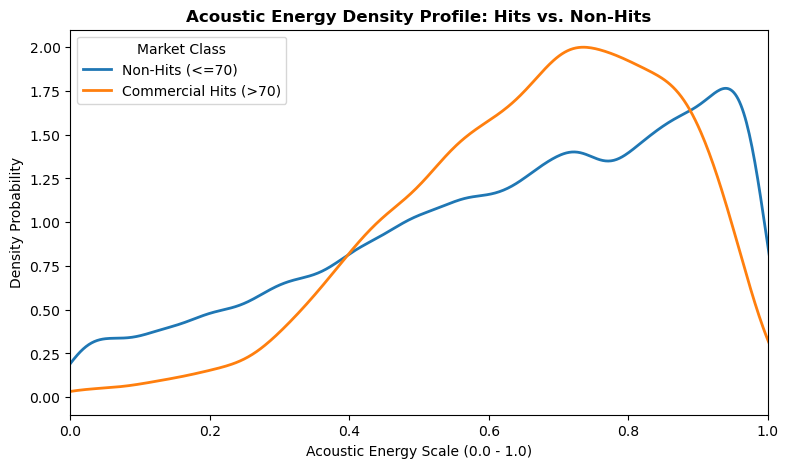

In [8]:
# STEP 3: ANALYZE
# Matplotlib Density Overlays ---
fig = plt.figure(figsize=(9, 5))

# Filter cohorts out of your clean dataframe
df[df['is_hit'] == 0]['energy'].plot(kind='density', label='Non-Hits (<=70)', linewidth=2)
df[df['is_hit'] == 1]['energy'].plot(kind='density', label='Commercial Hits (>70)', linewidth=2)

plt.title('Acoustic Energy Density Profile: Hits vs. Non-Hits', fontsize=12, fontweight='bold')
plt.xlabel('Acoustic Energy Scale (0.0 - 1.0)')
plt.ylabel('Density Probability')
plt.xlim(0, 1)
plt.legend(title='Market Class')
plt.show()


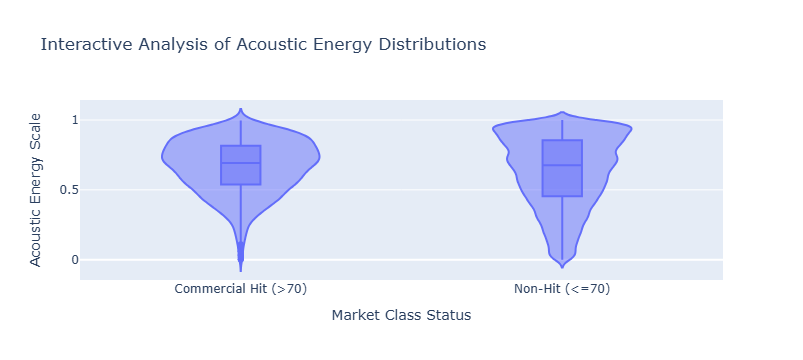

In [9]:
import plotly.express as px

# Plotly Express Interactive Violin ---
# Mapping 0 and 1 to clean text labels for presentation clarity
df['Market_Status'] = df['is_hit'].map({0: 'Non-Hit (<=70)', 1: 'Commercial Hit (>70)'})

fig = px.violin(df, 
                y='energy', 
                x='Market_Status', 
                box=True,          # Displays the internal boxplot layer as shown in class
                points='outliers', # Shows outlier distributions cleanly
                title='Interactive Analysis of Acoustic Energy Distributions',
                labels={'energy': 'Acoustic Energy Scale', 'Market_Status': 'Market Class Status'})

fig.show()


## Visual Data Analysis & Distribution Architecture

This section serves as our definitive **Step 4. Report** phase, summarizing our main visual findings and connecting them directly to our core research question: *Can a track's technical audio features predict its commercial success?*

Our continuous shape diagnostics expose a distinct, non-linear relationship between acoustic energy and consumer hit status:
* **The Audio Sweet Spot:** The Matplotlib continuous density overlay reveals that commercial hit probability favors balanced audio configurations, forming a sharp, dominant peak concentrated strictly between **0.65 and 0.80 acoustic energy**.
* **The Sound Saturation Barrier:** Conversely, commercially unsuccessful records ($is\_hit = 0$) exhibit a massive secondary spike peaking at the absolute extreme boundary (**~0.95 energy**), visually illustrating that over-saturated sensory noise is heavily characteristic of failed music.
* **Parabolic Hull Narrowing:** This trend is supported by our Plotly violin profiles, which display a sharp narrowing of the 'Commercial Hit' density hull at both extreme poles, highlighting a threshold of diminishing market returns for intense audio profiles.

### Substantive Dataset Limitations
Before transitioning this prepared matrix into a machine learning classification workspace, two critical constraints must be documented:
1. **Temporal Snapshot Stagnation:** The dataset represents a historical snapshot frozen in **October 2022**. Popularity metrics reflect a stagnant window of streaming velocity at the moment of extraction rather than modern real-time consumption patterns.
2. **Substantial Class Imbalance:** The target variable exhibits a severe class imbalance, with **only ~3.05% of the prepared tracks classified as hits**. Leaving this imbalance unmanaged would cause future algorithms to over-predict the majority class. This heavy skew provides a strong justification for deploying advanced class-weight balancing routines and tree-based ensemble models in the upcoming machine learning phase.


## Feature Selection and Stratified Data Partitioning
In this section, we extract our core quantitative audio metrics to build an end-to-end supervised machine learning classification pipeline. Due to the severe minority target skew (~3.05% hits) documented during data preparation, a standard randomized train/test split would introduce severe sampling bias. 

To guarantee strict class proportion distributions across our data splits, a stratified split is executed, allocating 75% of our cleaned data matrix to model training (67,199 observations) and 25% to an isolated holdout validation pool (22,400 observations).


In [10]:
# =====================================================================
# FEATURE SELECTION & STRATIFIED PARTITIONING
# =====================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- Automatic Data-Quality Safeguard ---
# If loudness_normalized is missing from this session, engineer it instantly from raw loudness
if 'loudness_normalized' not in df.columns and 'loudness' in df.columns:
    max_observed_loudness = df['loudness'].max()
    # Handle division by zero edge-case safely if max loudness is 0
    if max_observed_loudness != 0:
        df['loudness_normalized'] = df['loudness'] / max_observed_loudness
    else:
        df['loudness_normalized'] = df['loudness']
    print("✓ Automatically engineered 'loudness_normalized' from baseline features.")

# 1. Feature Matrix (X) and Categorical Class Target (y) Extraction
feature_cols = ['danceability', 'energy', 'loudness_normalized', 'speechiness', 'acousticness', 'tempo', 'valence']
X = df[feature_cols]
y = df['is_hit']

# 2. Stratified Train/Test Split Execution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("\n--- DATA PARTITION COMPLETION ---")
print(f"Training Feature Matrix Dimensions: {X_train.shape}")
print(f"Holdout Testing Matrix Dimensions: {X_test.shape}")


✓ Automatically engineered 'loudness_normalized' from baseline features.

--- DATA PARTITION COMPLETION ---
Training Feature Matrix Dimensions: (67199, 7)
Holdout Testing Matrix Dimensions: (22400, 7)
